In [1]:
# --- Setup (works locally and in Google Colab) ---
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("src").exists():
    !git clone https://github.com/ArjunGopal10/privacy-preserving-synthetic-graph-generation.git
    %cd privacy-preserving-synthetic-graph-generation
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from src.visualization.plot_style import apply_style
apply_style(); plt.rcParams["figure.dpi"] = 100
%matplotlib inline

# 05 · NSGA-II over epsilon
Minimise $[\varepsilon,\,-\mathbb E[Q]]$ (pymoo). Epsilon is the only variable, so a dense **grid search** is the reference. The pipeline is **not** end-to-end DP (the original graph is used to score candidates).

In [2]:
from src.graph_generation.graph_loader import load_karate_club
from src.community.community_detection import detect_communities
from src.optimization.fitness_functions import ExpectedModularityEvaluator
from src.optimization.nsga2_optimizer import NSGA2Config, run_nsga2, grid_search
from src.optimization.pareto_analysis import compare_with_grid, select_solutions
G = load_karate_club(); P0 = detect_communities(G, "louvain", seed=42)
cfg = NSGA2Config()               # pop 40, 30 generations, seed 42, SBX(0.9, 15), PM(20), K=20
res = run_nsga2(ExpectedModularityEvaluator(G, P0, cfg.n_releases, cfg.seed), cfg)
grid = grid_search(ExpectedModularityEvaluator(G, P0, cfg.n_releases, cfg.seed), 0.1, 10, 500)
stats = compare_with_grid(res.front, grid, cfg.hv_ref_point); print(stats)
res.generations[["generation", "hypervolume", "front_size", "best_expected_q"]].iloc[[0, 4, 9, 19, 29]]

{'hv_grid': 3.900886747514752, 'hv_nsga2': 3.8660028464760137, 'hv_ratio': 0.991057443269543, 'n_front_grid': 272, 'n_front_nsga2': 40, 'max_q_gap': 0.0005785456032099123, 'mean_q_gap': 3.276442652702644e-05}


,generation,hypervolume,front_size,best_expected_q
0,1,3.768529,28,0.384806
4,5,3.854475,40,0.384806
9,10,3.860447,40,0.384806
19,20,3.866754,40,0.384806
29,30,3.866003,40,0.384806


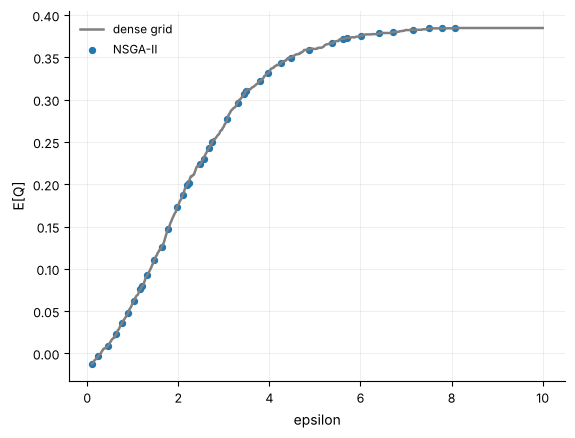

,label,epsilon,expected_q,utility_fraction
0,smallest eps with E[Q] >= 50% of Q0,2.190653,0.199306,0.517202
1,smallest eps with E[Q] >= 80% of Q0,3.490429,0.310429,0.805567
2,smallest eps with E[Q] >= 90% of Q0,4.469132,0.349841,0.907840
3,knee (max distance from diagonal),3.490429,0.310429,0.805567


In [3]:
plt.plot(grid.epsilon, grid.expected_q, color="grey", label="dense grid")
plt.scatter(res.front.epsilon, res.front.expected_q, s=18, label="NSGA-II"); plt.xlabel("epsilon"); plt.ylabel("E[Q]"); plt.legend(); plt.show()
select_solutions(res.front, 0.38535503)